# Customer Churn Analysis — Telecom

**Goal:** understand *who* leaves, *why* they leave, and *which* customers to target with retention offers.

Steps: data quality check → KPIs → churn drivers (EDA) → cohort view by tenure → predictive model → business recommendations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, RocCurveDisplay

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

df = pd.read_csv('data/telco_churn.csv')
df['churn_flag'] = (df['churn'] == 'Yes').astype(int)
df.head()

,customer_id,senior_citizen,partner,tenure_months,contract,internet_service,online_security,tech_support,streaming_tv,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_flag
0,CUST-00001,0,No,5,Two year,Fiber optic,No,No,Yes,Yes,Electronic check,78.81,398.16,Yes,1
1,CUST-00002,0,No,4,Month-to-month,DSL,Yes,No,No,Yes,Bank transfer,42.54,165.94,No,0
2,CUST-00003,0,No,18,Two year,DSL,No,No,No,No,Electronic check,46.15,816.79,No,0
3,CUST-00004,0,Yes,11,One year,Fiber optic,No,No,Yes,Yes,Credit card,82.04,925.31,No,0
4,CUST-00005,0,Yes,11,Month-to-month,DSL,No,No,Yes,No,Mailed check,60.04,630.79,No,0


## 1. Data quality check

In [2]:
print(df.shape)
print('Duplicate IDs:', df['customer_id'].duplicated().sum())
print('Missing values:', df.isna().sum().sum())
df.describe().round(2)

(7000, 15)
Duplicate IDs: 0
Missing values: 0


,senior_citizen,tenure_months,monthly_charges,total_charges,churn_flag
count,7000.00,7000.00,7000.00,7000.00,7000.00
mean,0.16,19.73,56.63,1116.74,0.25
std,0.36,13.64,23.78,959.17,0.44
min,0.00,1.00,6.44,11.06,0.00
25%,0.00,9.00,41.94,392.60,0.00
50%,0.00,17.00,60.23,832.88,0.00
75%,0.00,27.00,76.67,1585.40,1.00
max,1.00,72.00,103.35,6300.92,1.00


## 2. Headline KPIs

In [3]:
kpi = pd.Series({
    'Customers': len(df),
    'Churn rate': f"{df.churn_flag.mean():.1%}",
    'Monthly revenue lost (AZN)': f"{df.loc[df.churn_flag == 1, 'monthly_charges'].sum():,.0f}",
    'Share of revenue lost': f"{df.loc[df.churn_flag == 1, 'monthly_charges'].sum() / df.monthly_charges.sum():.1%}",
    'Avg tenure — churned (months)': round(df.loc[df.churn_flag == 1, 'tenure_months'].mean(), 1),
    'Avg tenure — retained (months)': round(df.loc[df.churn_flag == 0, 'tenure_months'].mean(), 1),
})
kpi.to_frame('value')

,value
Customers,7000
Churn rate,25.5%
Monthly revenue lost (AZN),"113,024"
Share of revenue lost,28.5%
Avg tenure — churned (months),13.6
Avg tenure — retained (months),21.8


## 3. Churn drivers — categorical features

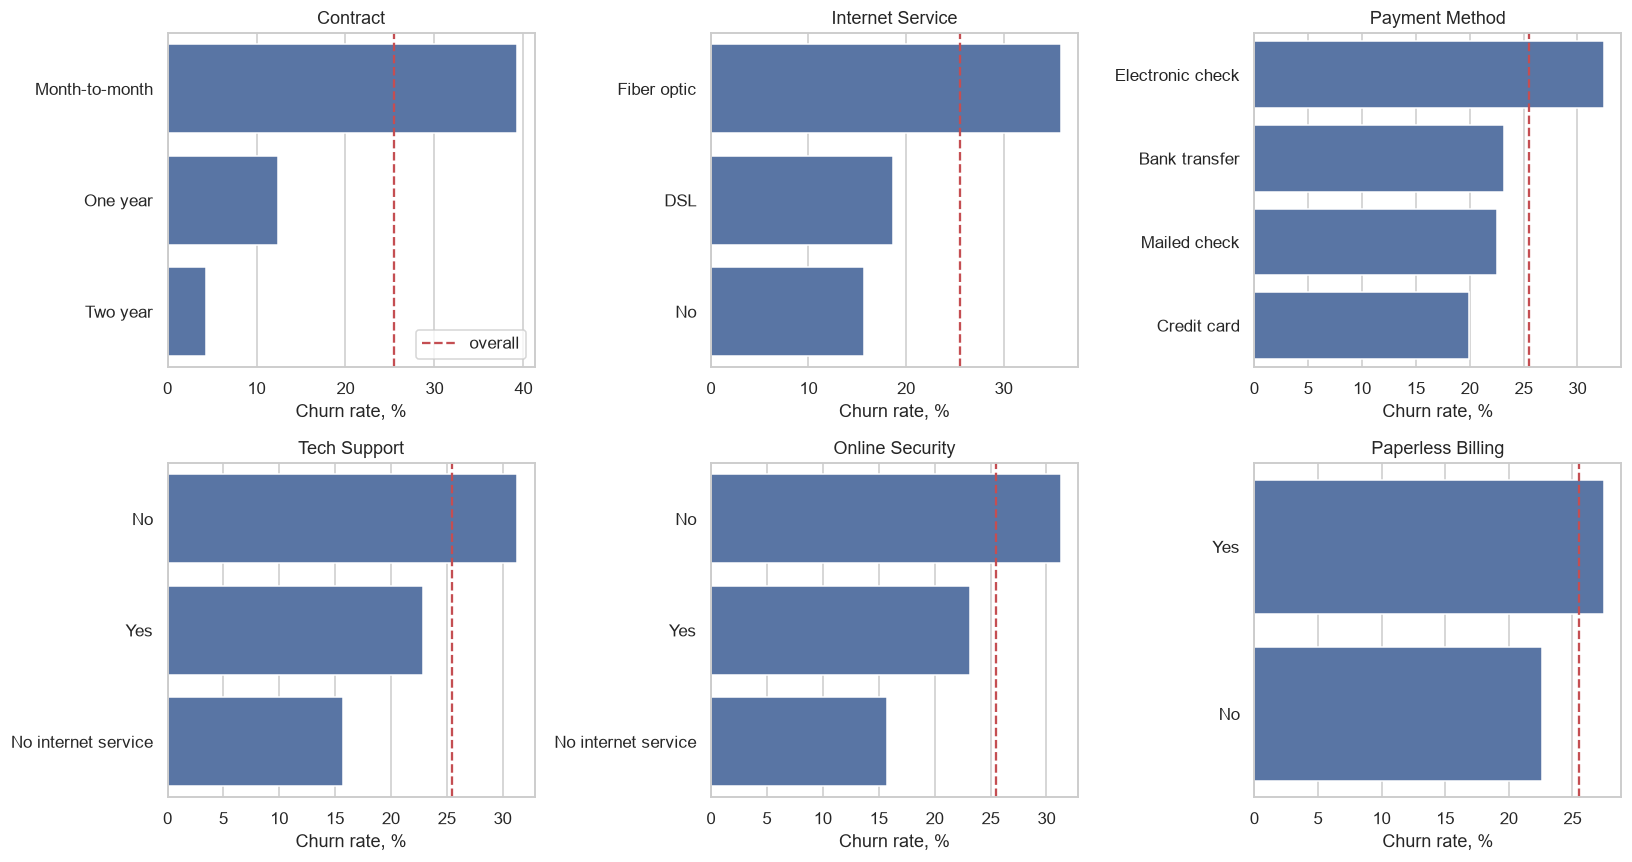

In [4]:
cats = ['contract', 'internet_service', 'payment_method', 'tech_support', 'online_security', 'paperless_billing']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cats):
    rate = df.groupby(col)['churn_flag'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values * 100, y=rate.index, ax=ax, color='#4C72B0')
    ax.axvline(df.churn_flag.mean() * 100, ls='--', color='#C44E52', label='overall')
    ax.set(title=col.replace('_', ' ').title(), xlabel='Churn rate, %', ylabel='')
axes.flat[0].legend()
plt.tight_layout()
plt.savefig('images/churn_by_category.png', bbox_inches='tight')
plt.show()

## 4. Tenure & charges

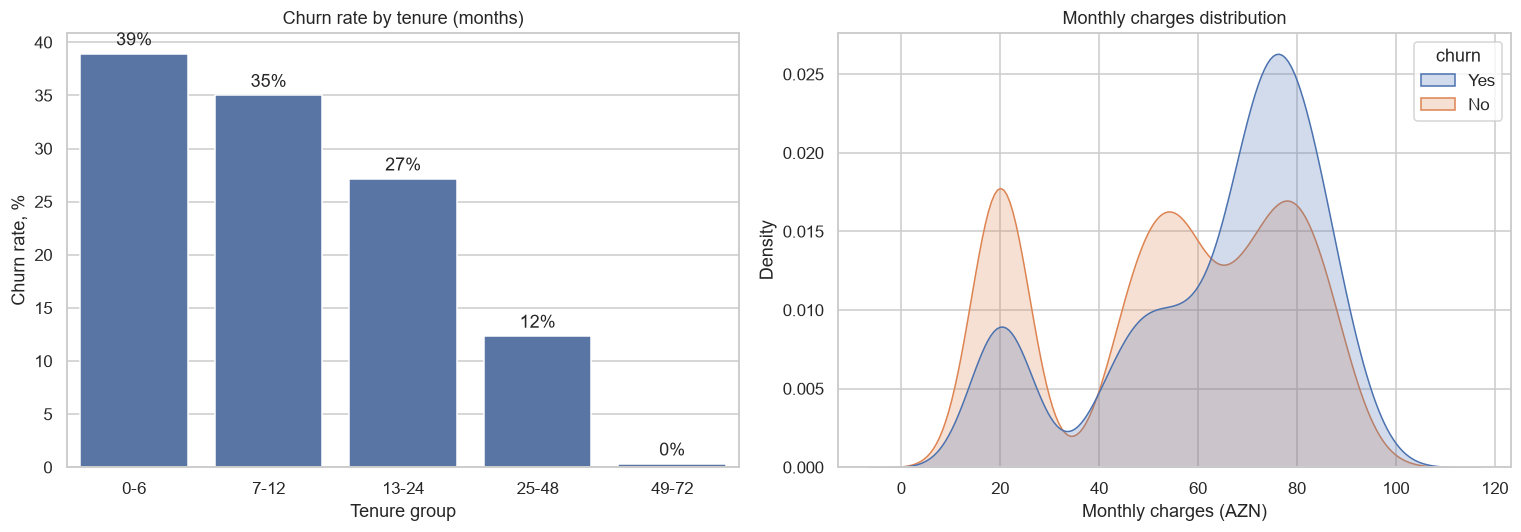

In [5]:
df['tenure_group'] = pd.cut(df.tenure_months, [0, 6, 12, 24, 48, 72],
                            labels=['0-6', '7-12', '13-24', '25-48', '49-72'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tg = df.groupby('tenure_group', observed=True)['churn_flag'].mean() * 100
sns.barplot(x=tg.index, y=tg.values, ax=axes[0], color='#4C72B0')
axes[0].set(title='Churn rate by tenure (months)', ylabel='Churn rate, %', xlabel='Tenure group')
for i, v in enumerate(tg.values):
    axes[0].text(i, v + 0.8, f'{v:.0f}%', ha='center')
sns.kdeplot(data=df, x='monthly_charges', hue='churn', fill=True, common_norm=False, ax=axes[1])
axes[1].set(title='Monthly charges distribution', xlabel='Monthly charges (AZN)')
plt.tight_layout()
plt.savefig('images/tenure_and_charges.png', bbox_inches='tight')
plt.show()

## 5. Risk heatmap: contract × internet service

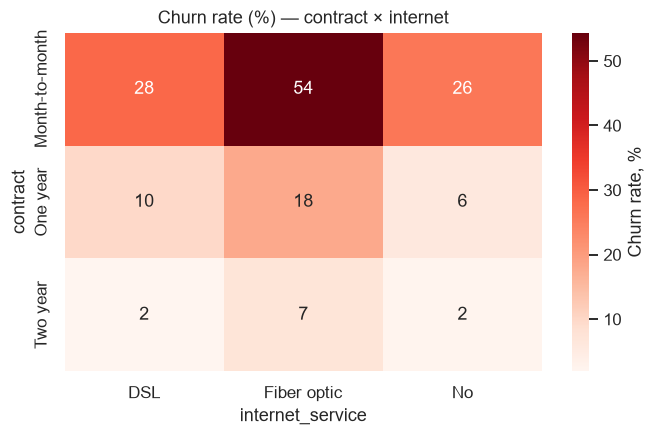

In [6]:
pivot = df.pivot_table(index='contract', columns='internet_service', values='churn_flag', aggfunc='mean') * 100
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Churn rate, %'})
plt.title('Churn rate (%) — contract × internet')
plt.savefig('images/risk_heatmap.png', bbox_inches='tight')
plt.show()

## 6. Predictive model — logistic regression

Interpretable model so the business can see *which* factors push risk up or down.

In [7]:
features = ['senior_citizen', 'partner', 'tenure_months', 'contract', 'internet_service', 'online_security',
            'tech_support', 'streaming_tv', 'paperless_billing', 'payment_method', 'monthly_charges']
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df.churn_flag
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=1000, class_weight='balanced').fit(scaler.transform(X_train), y_train)
proba = model.predict_proba(scaler.transform(X_test))[:, 1]
print(f'ROC-AUC: {roc_auc_score(y_test, proba):.3f}\n')
print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=['Stay', 'Churn']))

ROC-AUC: 0.812

              precision    recall  f1-score   support

        Stay       0.90      0.71      0.79      1304
       Churn       0.48      0.78      0.59       446

    accuracy                           0.73      1750
   macro avg       0.69      0.74      0.69      1750
weighted avg       0.80      0.73      0.74      1750



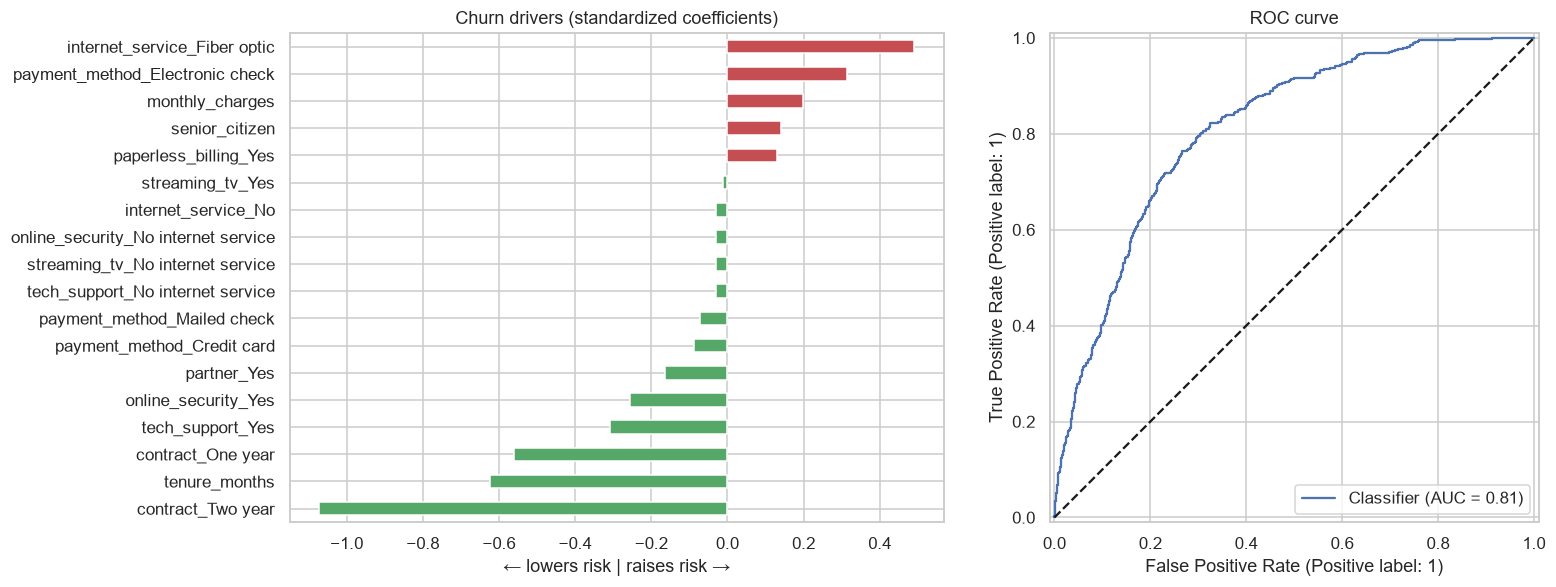

In [8]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
coef.plot.barh(ax=axes[0], color=np.where(coef > 0, '#C44E52', '#55A868'))
axes[0].set(title='Churn drivers (standardized coefficients)', xlabel='← lowers risk | raises risk →')
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC curve')
plt.tight_layout()
plt.savefig('images/model_drivers_roc.png', bbox_inches='tight')
plt.show()

## 7. Who to target — risk segments

In [9]:
df['churn_risk'] = model.predict_proba(scaler.transform(X))[:, 1]
df['risk_segment'] = pd.cut(df.churn_risk, [0, 0.3, 0.6, 1], labels=['Low', 'Medium', 'High'])
seg = df.groupby('risk_segment', observed=True).agg(customers=('customer_id', 'count'),
                                    actual_churn_rate=('churn_flag', 'mean'),
                                    monthly_revenue=('monthly_charges', 'sum'))
seg['actual_churn_rate'] = (seg.actual_churn_rate * 100).round(1)
seg

,customers,actual_churn_rate,monthly_revenue
risk_segment,,,
Low,2705,4.8,139614.89
Medium,2048,22.7,105972.38
High,2247,52.9,150855.48


## 8. Key findings & recommendations

| Finding | Recommendation |
|---|---|
| Month-to-month customers churn several times more than two-year customers | Offer a discount for switching to a 1-/2-year contract |
| Highest risk is in the **first 6 months** | Onboarding programme: welcome call, first-month check-in |
| Fiber customers without tech support / security churn most | Bundle free tech support for the first 3 months |
| Electronic-check payers churn more | Incentivise auto-pay (card / bank transfer) |
| Model ranks customers by risk (ROC-AUC shown above) | Focus the retention budget on the **High** risk segment |